# Model 02: Product Demand Estimation
### College Data Mining & DWDM Laboratory Submission
**Algorithm:** KNN Regression  
**Problem Type:** Continuous Regression with Feature Scaling  
**Key Concepts Demonstrated:**
- Syllabus-aligned algorithm implementation
- Data preprocessing & descriptive statistics
- Model training, hyperparameter tuning & evaluation
- Joblib model serialization and sample inference


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Ensure parent directory is in path
sys.path.append(os.path.abspath(".."))
from preprocessing.preprocess import load_dataset, clean_and_impute

# Load and clean dataset
df = load_dataset()
df_clean = clean_and_impute(df)
print(f"Dataset ready: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head(3)


Dataset ready: 1000 rows, 30 columns


,date,day_of_week,is_weekend,product_name,category,price,discount,previous_day_sales,sales_7_day_average,sales_30_day_average,...,sales_90_day,turnover_rate,days_since_last_sale,category_label,inventory_status,business_activity,total_expense,expense_3_month_average,average_order_value,profit
0,2024-01-01,Monday,0,Laundry Detergent 1kg,Household,210.0,10.43,3599.34,3599.34,3599.34,...,205357.08,3.62,12,MEDIUM_DEMAND,RESTOCK,14.87,3044.67,3044.67,97.28,-275.43
1,2024-01-02,Tuesday,0,Basmati Rice 5kg,Grocery,450.0,2.96,3599.34,3656.81,3656.81,...,316258.19,3.77,1,MEDIUM_DEMAND,RESTOCK,15.39,3100.65,3072.66,95.24,-358.75
2,2024-01-03,Wednesday,0,Organic Honey 500g,Grocery,280.0,6.88,3714.28,3750.13,3750.13,...,159407.77,5.20,0,MEDIUM_DEMAND,RESTOCK,12.33,3445.75,3197.02,115.79,-448.90


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

feature_cols = ["current_stock", "demand_7_day", "demand_30_day", "average_daily_demand", "price", "discount"]
X = df_clean[feature_cols].values
y = df_clean["predicted_demand"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Cross Validation for K in [3, 5, 7, 9, 11]
k_candidates = [3, 5, 7, 9, 11]
cv_scores = {}
for k in k_candidates:
    pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=k, weights='distance'))])
    scores = -cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
    cv_scores[k] = float(np.mean(scores))
    print(f"K={k:2d} | 5-Fold CV MAE: {cv_scores[k]:.3f} units")

best_k = min(cv_scores, key=cv_scores.get)
print(f"\nOptimal K Selected: K = {best_k}")


K= 3 | 5-Fold CV MAE: 5.196 units
K= 5 | 5-Fold CV MAE: 5.033 units
K= 7 | 5-Fold CV MAE: 5.051 units
K= 9 | 5-Fold CV MAE: 5.047 units
K=11 | 5-Fold CV MAE: 5.040 units

Optimal K Selected: K = 5


Test Set MAE:  4.74 units
Test Set RMSE: 7.51 units
Test Set R²:   0.9504


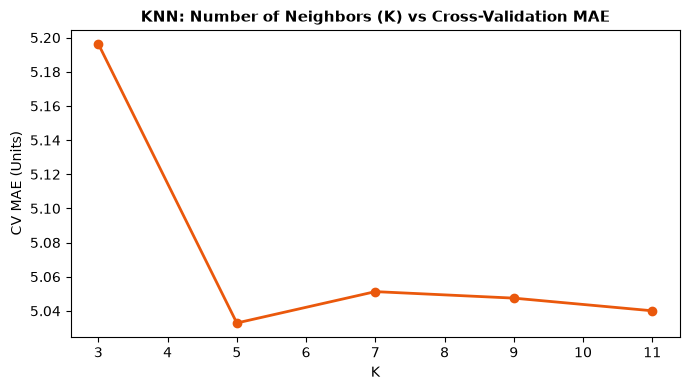

In [3]:
# Fit Final Model and Evaluate
best_pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=best_k, weights='distance'))])
best_pipe.fit(X_train, y_train)
y_pred = best_pipe.predict(X_test)

print(f"Test Set MAE:  {mean_absolute_error(y_test, y_pred):.2f} units")
print(f"Test Set RMSE: {root_mean_squared_error(y_test, y_pred):.2f} units")
print(f"Test Set R²:   {r2_score(y_test, y_pred):.4f}")

# Plot K vs CV MAE
plt.figure(figsize=(7, 4))
plt.plot(list(cv_scores.keys()), list(cv_scores.values()), marker='o', color='#ea580c', lw=2)
plt.title("KNN: Number of Neighbors (K) vs Cross-Validation MAE", fontsize=11, fontweight='bold')
plt.xlabel("K")
plt.ylabel("CV MAE (Units)")
plt.tight_layout()
plt.show()


In [4]:
# Joblib Save & Business Rule Demo
joblib.dump(best_pipe, "../models/demand_model.joblib")
del best_pipe
loaded_pipe = joblib.load("../models/demand_model.joblib")

sample = np.array([[80, 120.0, 500.0, 18.0, 65.0, 5.0]])
predicted_units = int(round(loaded_pipe.predict(sample)[0]))
current_stock = int(sample[0][0])
shortage = max(0, predicted_units - current_stock)

print(f"Current Stock:    {current_stock} units")
print(f"Predicted Demand: {predicted_units} units")
print(f"Shortage/Deficit: {shortage} units")
print(f"Business Action:  {'RESTOCK ' + str(shortage) + ' UNITS' if shortage > 0 else 'STOCK SUFFICIENT'}")


Current Stock:    80 units
Predicted Demand: 120 units
Shortage/Deficit: 40 units
Business Action:  RESTOCK 40 UNITS
